# **NSL Dataset Exploratory & Processing**

In [62]:
# import relevant dependencies
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pyod.models.ecod import ECOD
from pyod.models.iforest import IForest
from sklearn.metrics import average_precision_score

In [63]:
# read in dataset
df = pd.read_csv('/Users/han./Desktop/CS5344/data/raw/NSL-KDD_train.csv')
print(df.shape)
df.info()

(30000, 42)
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 42 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   duration                     30000 non-null  int64  
 1   src_bytes                    30000 non-null  int64  
 2   dst_bytes                    30000 non-null  int64  
 3   land                         30000 non-null  int64  
 4   wrong_fragment               30000 non-null  int64  
 5   urgent                       30000 non-null  int64  
 6   hot                          30000 non-null  int64  
 7   num_failed_logins            30000 non-null  int64  
 8   logged_in                    30000 non-null  int64  
 9   num_compromised              30000 non-null  int64  
 10  root_shell                   30000 non-null  int64  
 11  su_attempted                 30000 non-null  int64  
 12  num_root                     30000 non-null  int64  
 13  num_file_creati

---
**Class Imbalance**

/var/folders/9w/mhdmp23914sfc62d1t8ng_dr0000gn/T/ipykernel_61695/394415553.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Normal (0)', 'Abnormal (1)'])


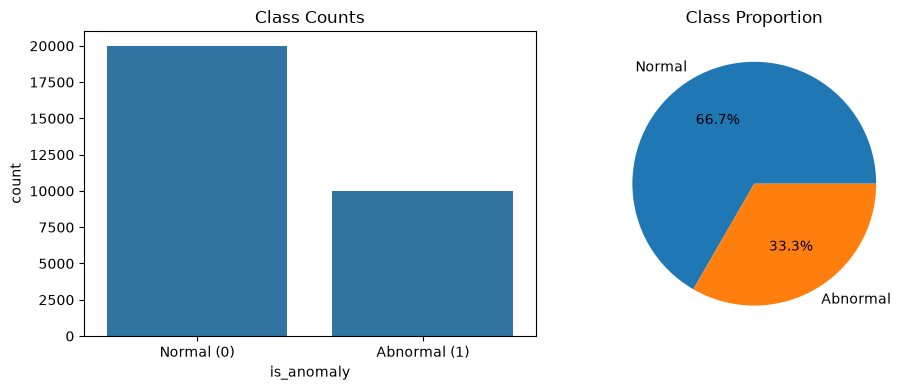

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Bar count
sns.countplot(data=df, x='is_anomaly', ax=axes[0])
axes[0].set_xticklabels(['Normal (0)', 'Abnormal (1)'])
axes[0].set_title('Class Counts')

# Pie / proportion
df['is_anomaly'].value_counts().plot.pie(
    labels=['Normal', 'Abnormal'], autopct='%1.1f%%', ax=axes[1]
)
axes[1].set_ylabel('')
axes[1].set_title('Class Proportion')

plt.tight_layout()
plt.show()

----
**Analysis on Categorial Features**

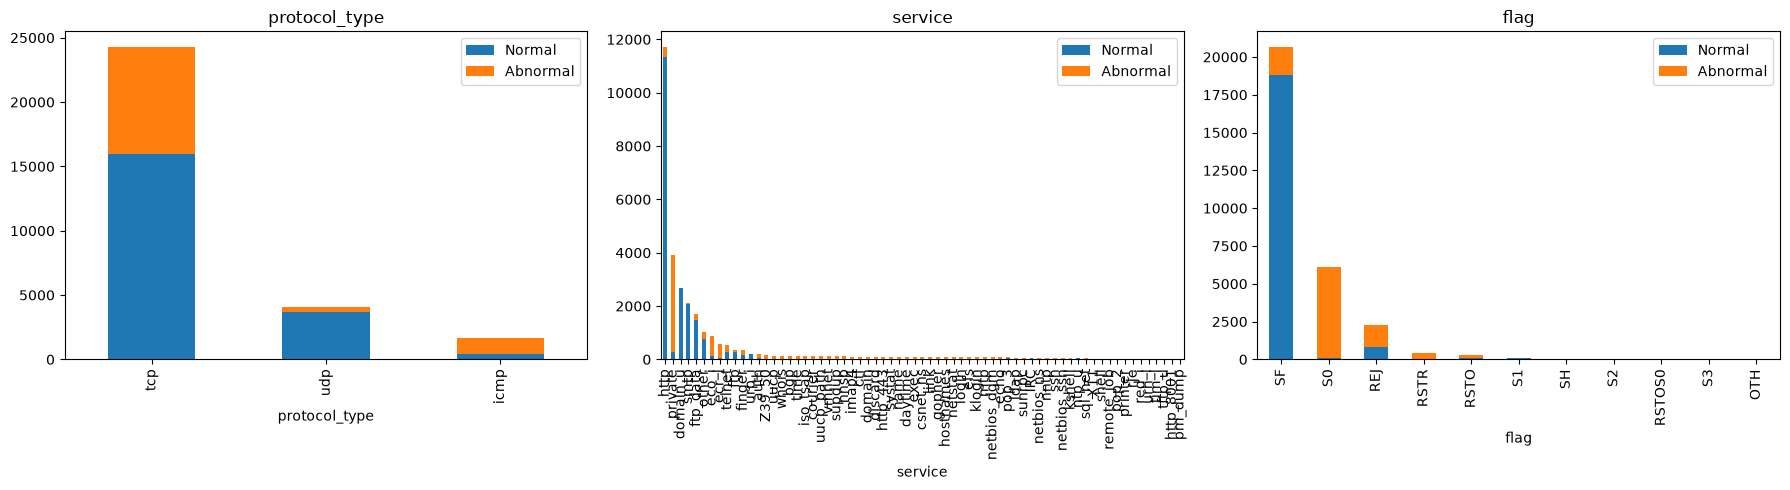

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(['protocol_type', 'service', 'flag']):
    ct = pd.crosstab(df[col], df['is_anomaly'])
    ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]  # sort by frequency
    ct.plot(kind='bar', stacked=True, ax=axes[i])
    axes[i].set_title(col)
    axes[i].legend(['Normal', 'Abnormal'])

plt.tight_layout()
plt.show()

- Flag is the strongest categorical signal. Normal traffic has a very distinctive narrow flag fingerprint. Synthetic normal data should overwhelmingly sample flag = SF, matching the real conditional distribution P(flag|normal).
- Protocol Type carries moderate signal, not a clean seperator , generator should preserve P(protocoal_type|normal), likely skewing away from raw training distribution.
- Service has moderate signal, dont overfit to rare service categories, focus on preserving dominant categories

Basically train the whole generator only on like clean data

---

**Check Which Features are Near Constant and Which are Heavily Skewed**

In [66]:
normal_df = df[df['is_anomaly'] == 0]
numeric_cols = [c for c in df.select_dtypes(include='number').columns if c != 'is_anomaly']

# 1. Zero-inflation: which columns are mostly 0?
zero_report = normal_df[numeric_cols].eq(0).mean().sort_values(ascending=False)
print("=== % zeros per feature ===")
print(zero_report[zero_report > 0.5])

# 2. Skewness: which columns have long tails?
from scipy.stats import skew
skew_report = normal_df[numeric_cols].apply(lambda x: skew(x)).sort_values(ascending=False)
print("\n=== Top skewed features ===")
print(skew_report.head(15))

=== % zeros per feature ===
num_outbound_cmds           1.00000
wrong_fragment              1.00000
is_host_login               1.00000
land                        0.99990
urgent                      0.99990
num_shells                  0.99930
num_failed_logins           0.99890
su_attempted                0.99875
root_shell                  0.99750
num_file_creations          0.99555
num_access_files            0.99450
num_compromised             0.99450
num_root                    0.99055
is_guest_login              0.98715
hot                         0.98085
serror_rate                 0.96440
srv_serror_rate             0.96275
rerror_rate                 0.95185
srv_rerror_rate             0.94610
diff_srv_rate               0.93135
dst_host_srv_serror_rate    0.91890
dst_host_serror_rate        0.90835
dst_host_srv_rerror_rate    0.90735
dst_host_rerror_rate        0.89100
duration                    0.88170
srv_diff_host_rate          0.63545
dst_host_diff_srv_rate      0.59955


For each numeric feature, apply the same procedure — there is no A/B/C split by feature name:

1. **Compute `p = P(feature == 0)`** on the normal-only subset
2. **Model the zero/nonzero split** as a Bernoulli(`p`)
3. **Fit a distribution only on the nonzero values** (apply `log1p` first if skewed, then fit e.g. log-normal)
4. **To generate a synthetic value:** flip the Bernoulli(`p`) → if "zero," output 0; if "nonzero," sample from the fitted nonzero distribution (then inverse-transform if log1p was applied)

**Edge case:** if a feature has very few nonzero values (e.g. <20), don't fit a parametric distribution on them — resample directly from the empirical nonzero values instead.

**Why one rule, no cutoff:**
- Zero-percentage is a continuous spectrum (100% → 88% → 60%), not naturally clustered — any manual cutoff is arbitrary
- One consistent rule generalizes automatically: a 100%-zero feature naturally collapses to "always 0" (p=1, no nonzero values to model); a 60%-zero feature just gets a smaller Bernoulli p
- Keeps the pipeline transferable to UNSW-NB15 without re-deciding thresholds per dataset


---
**Bounded Rate Features**

In [67]:
rate_cols = [c for c in numeric_cols if 'rate' in c]

for col in rate_cols:
    zero_pct = (normal_df[col] == 0).mean()
    one_pct = (normal_df[col] == 1).mean()
    mid_pct = 1 - zero_pct - one_pct
    print(f"{col}: 0%={zero_pct:.2%}, 1%={one_pct:.2%}, in-between={mid_pct:.2%}")

serror_rate: 0%=96.44%, 1%=0.61%, in-between=2.95%
srv_serror_rate: 0%=96.28%, 1%=0.50%, in-between=3.23%
rerror_rate: 0%=95.19%, 1%=4.13%, in-between=0.69%
srv_rerror_rate: 0%=94.61%, 1%=4.06%, in-between=1.32%
same_srv_rate: 0%=0.05%, 1%=94.03%, in-between=5.92%
diff_srv_rate: 0%=93.14%, 1%=1.48%, in-between=5.38%
srv_diff_host_rate: 0%=63.54%, 1%=6.69%, in-between=29.76%
dst_host_same_srv_rate: 0%=1.49%, 1%=63.14%, in-between=35.37%
dst_host_diff_srv_rate: 0%=59.96%, 1%=0.10%, in-between=39.95%
dst_host_same_src_port_rate: 0%=33.13%, 1%=3.79%, in-between=63.07%
dst_host_srv_diff_host_rate: 0%=49.82%, 1%=0.15%, in-between=50.03%
dst_host_serror_rate: 0%=90.83%, 1%=0.10%, in-between=9.07%
dst_host_srv_serror_rate: 0%=91.89%, 1%=0.04%, in-between=8.06%
dst_host_rerror_rate: 0%=89.10%, 1%=2.96%, in-between=7.93%
dst_host_srv_rerror_rate: 0%=90.73%, 1%=1.87%, in-between=7.40%


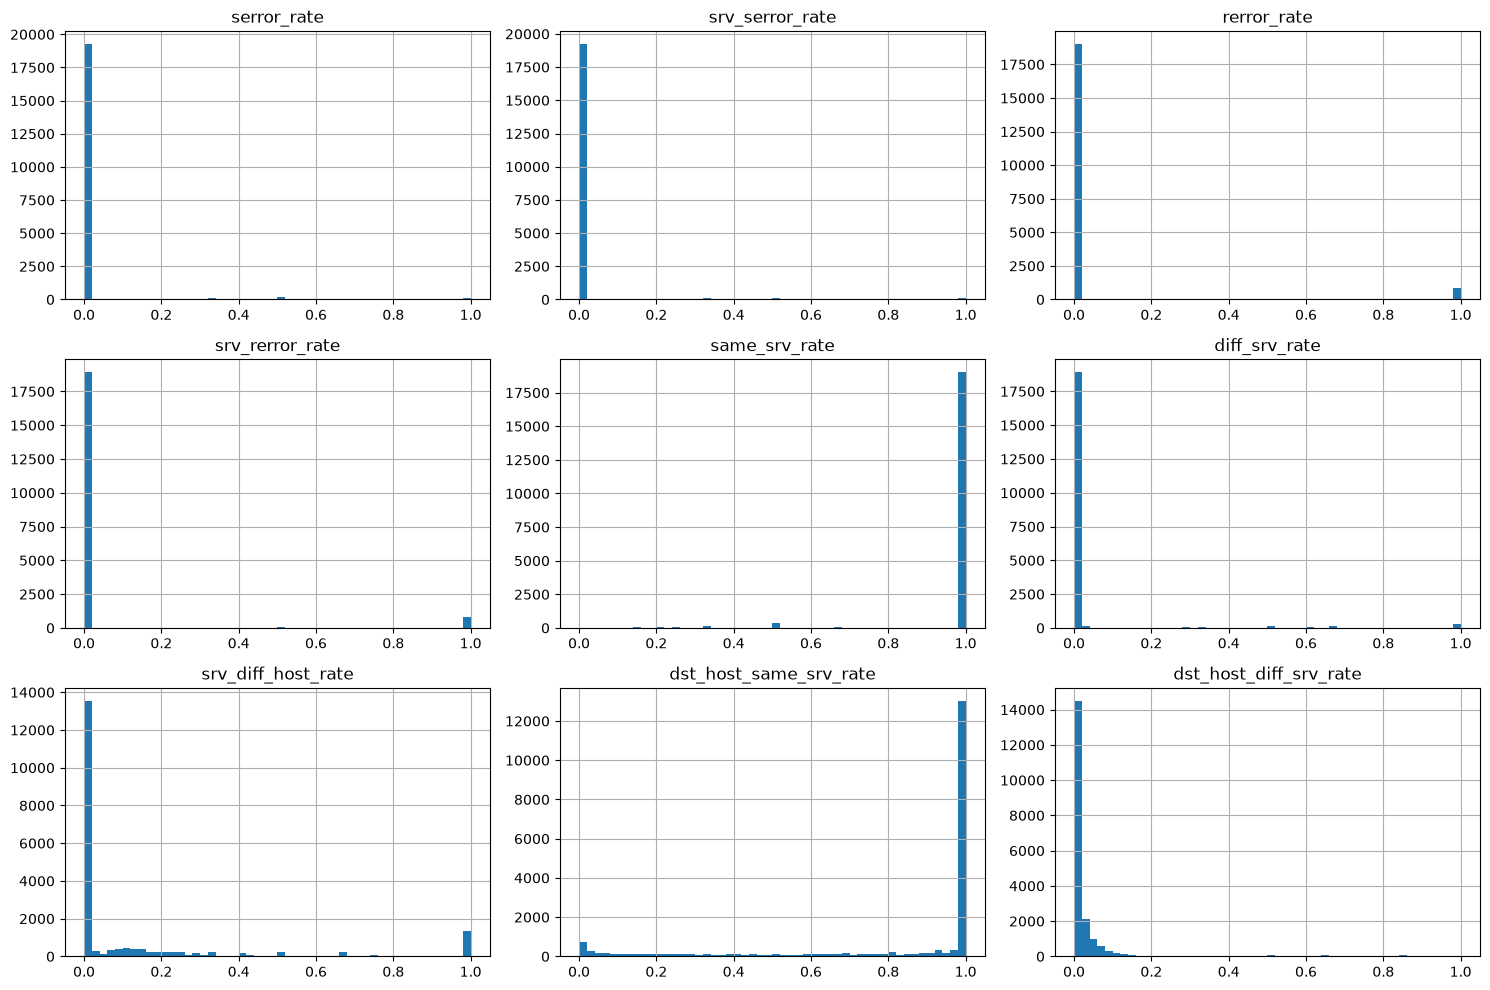

In [68]:
# Visualize a few to see the shape
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.flatten(), rate_cols[:9]):
    normal_df[col].hist(bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

- **Mostly 0-spiked, small/negligible 1-spike** (close to Phase 2's simple case):
  `serror_rate`, `srv_serror_rate`, `srv_rerror_rate`, `diff_srv_rate`,
  `srv_diff_host_rate`, `dst_host_diff_srv_rate`
- **Two-spike (0 AND 1), visible mass at both ends**:
  `rerror_rate`
- **Dominant spike at 1** (flipped pattern — most normal traffic scores near 1 here):
  `same_srv_rate`
- **Genuinely bimodal** (real mass at both 0 and 1, plus spread in between):
  `dst_host_same_srv_rate`


Instead of Phase 2's 2-part model, use a **3-part model**:
1. Compute `P(feature == 0)`
2. Compute `P(feature == 1)`
3. Fit a distribution only on the strictly-in-between values (0 < x < 1)

**To generate a synthetic value:** draw from a 3-outcome categorical
(zero / one / in-between) using the fitted probabilities; if "in-between," sample
from the fitted middle distribution

---
**Feature Correlation**

In [69]:
corr_matrix = normal_df[numeric_cols].corr()

# Find highly correlated pairs (excluding self-correlation)
corr_pairs = corr_matrix.abs().unstack()
corr_pairs = corr_pairs[corr_pairs < 1.0]  # remove self-correlation
corr_pairs = corr_pairs.sort_values(ascending=False)
corr_pairs = corr_pairs[~corr_pairs.index.duplicated()]  # dedupe symmetric pairs

print("=== Top correlated feature pairs ===")
print(corr_pairs.head(20))

=== Top correlated feature pairs ===
num_compromised           num_root                    0.995846
num_root                  num_compromised             0.995846
rerror_rate               srv_rerror_rate             0.983316
srv_rerror_rate           rerror_rate                 0.983316
count                     srv_count                   0.940814
srv_count                 count                       0.940814
dst_host_srv_rerror_rate  rerror_rate                 0.882560
rerror_rate               dst_host_srv_rerror_rate    0.882560
srv_rerror_rate           dst_host_srv_rerror_rate    0.878054
dst_host_srv_rerror_rate  srv_rerror_rate             0.878054
dst_host_rerror_rate      dst_host_srv_rerror_rate    0.875805
dst_host_srv_rerror_rate  dst_host_rerror_rate        0.875805
rerror_rate               dst_host_rerror_rate        0.866102
dst_host_rerror_rate      rerror_rate                 0.866102
srv_serror_rate           serror_rate                 0.864538
serror_rate       

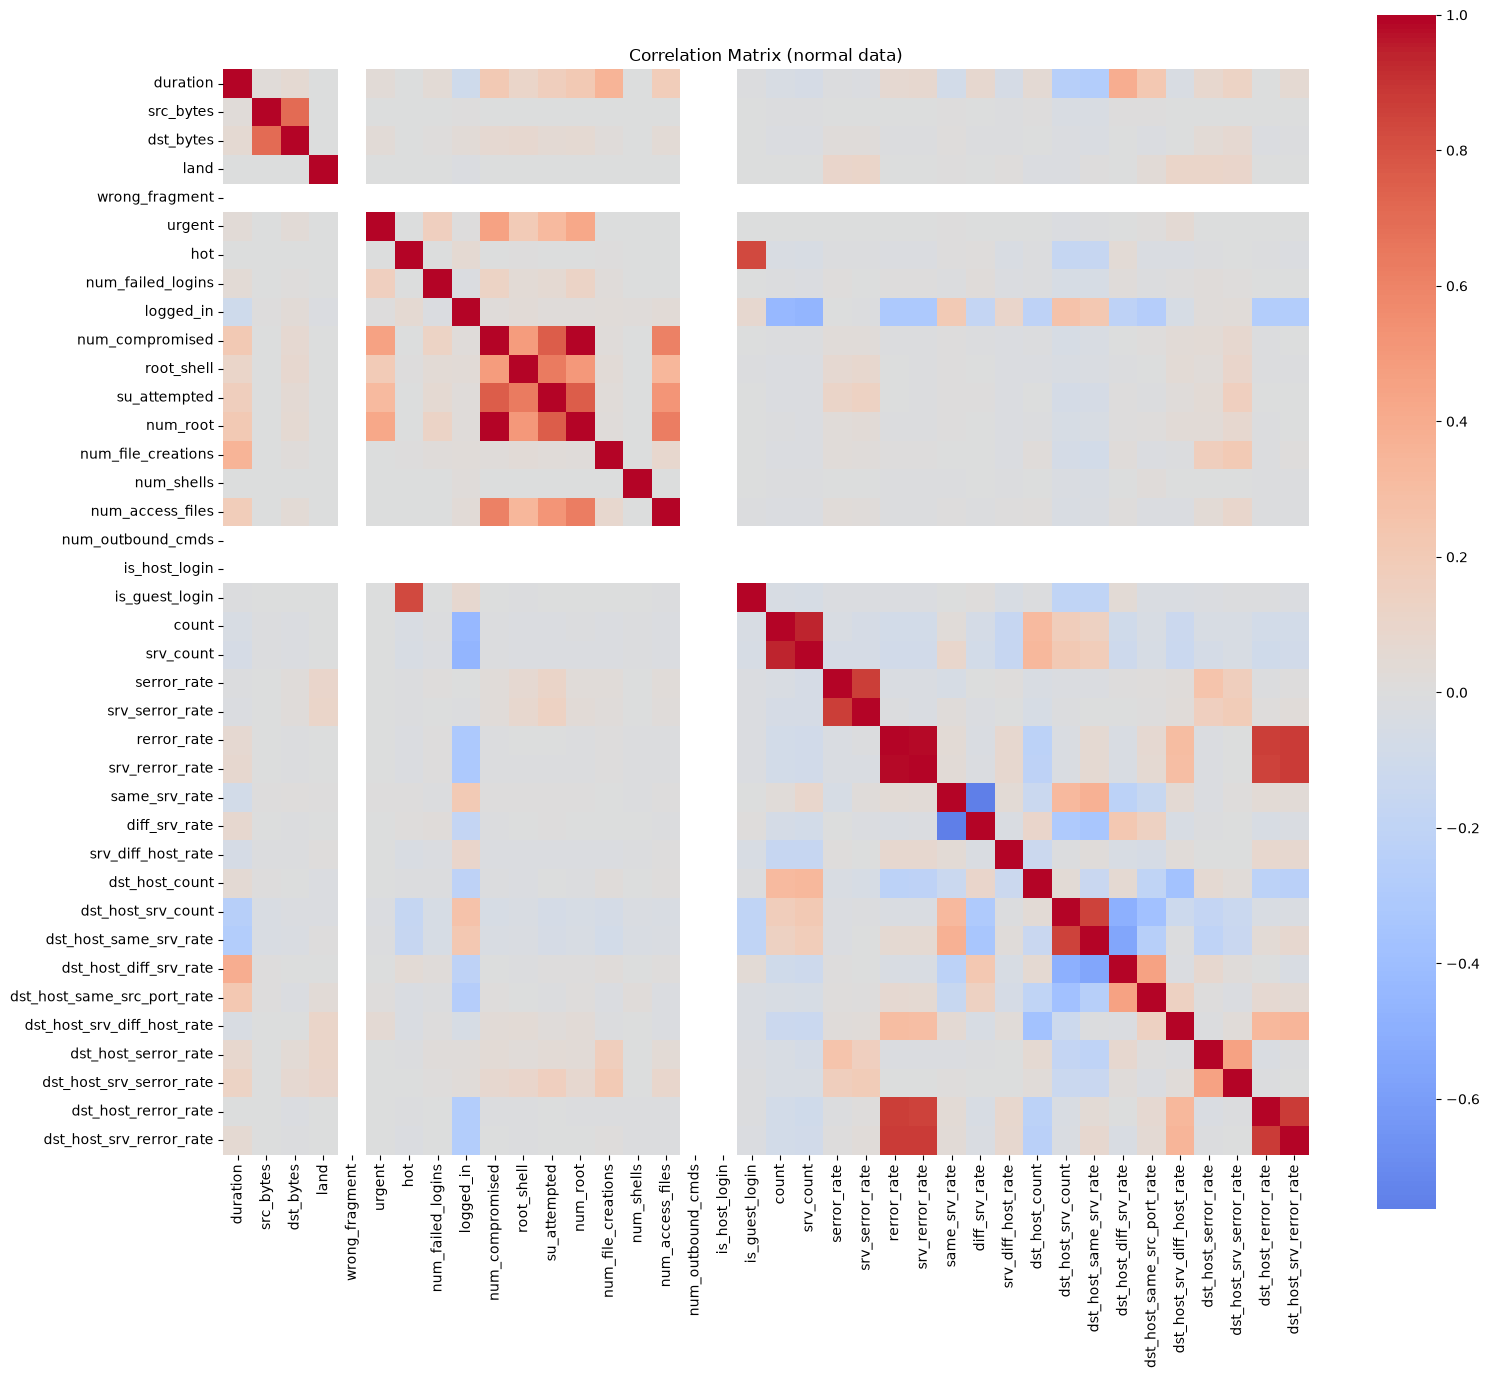

In [70]:
plt.figure(figsize=(16, 14))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, square=True)
plt.title("Correlation Matrix (normal data)")
plt.tight_layout()
plt.show()

**Why this matters:** if features are generated independently, real relationships
between them get broken. Multivariate detectors (like Isolation Forest) rely on
these relationships to judge whether a point looks "normal" — so ignoring them
risks synthetic data that looks fine feature-by-feature but is jointly unrealistic.

**1. "Root/compromise" cluster (~0.99 correlation)**
`num_compromised`, `root_shell`, `su_attempted`, `num_root`
— all fire together when a host is compromised and root access is gained.
Weaker links to `hot`, `num_access_files`.

**2. "Error rate" cluster (redundant/duplicate signal)**
- `rerror_rate` ↔ `srv_rerror_rate`: 0.98
- `rerror_rate` / `srv_rerror_rate` ↔ `dst_host_rerror_rate` / `dst_host_srv_rerror_rate`: 0.85–0.88
- `serror_rate` ↔ `srv_serror_rate`: 0.86
— these measure essentially the same "error rate" concept at different aggregation
windows (per-connection / per-service / per-host).

**3. "Traffic volume" pair**
`count` ↔ `srv_count`: 0.94 — both count connections in the same 2-second window,
sliced by host vs. service.

**4. Near-complementary negative correlation (structural constraint)**
`same_srv_rate` ↔ `diff_srv_rate`: ≈ -0.75 to -0.8
— these are near-complementary by definition (same_srv_rate + diff_srv_rate ≈ 1).
Must be preserved jointly; generating independently risks impossible combinations
(both high at once).

**5. Windowed redundancy**
`dst_host_same_srv_rate` ↔ `dst_host_srv_count`: 0.85 — same underlying signal,
measured at different aggregation levels.


Given the extent of redundancy and coupling, **independent per-feature sampling
is not sufficient** — it would break structure that downstream detectors rely on.
Favor a method that preserves joint structure, such as:
- **Copula-based generation**: fit marginals per feature (per Phase 2/3 rules),
  then model dependency structure separately (e.g. Gaussian copula) to stitch
  them together
- **A generative model that learns joint structure directly** (VAE, GMM, etc.)
  — captures correlations without manually specifying clusters

---
**Dimensionality View**

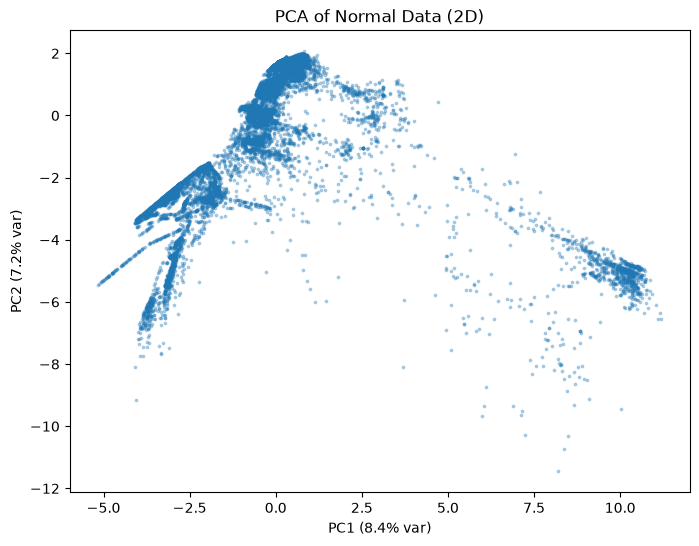

In [71]:
# Encode categoricals numerically for this step (one-hot is fine for PCA/UMAP)
normal_encoded = pd.get_dummies(normal_df[numeric_cols + ['protocol_type', 'service', 'flag']],
                                  columns=['protocol_type', 'service', 'flag'])

# Scale before PCA (important — otherwise byte-count features dominate)
scaled = StandardScaler().fit_transform(normal_encoded)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled)

plt.figure(figsize=(8,6))
plt.scatter(pca_result[:,0], pca_result[:,1], s=3, alpha=0.3)
plt.title("PCA of Normal Data (2D)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var)")
plt.show()

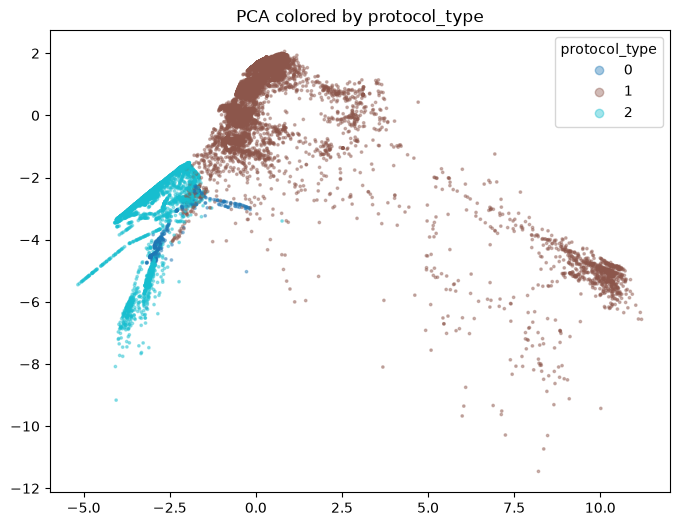

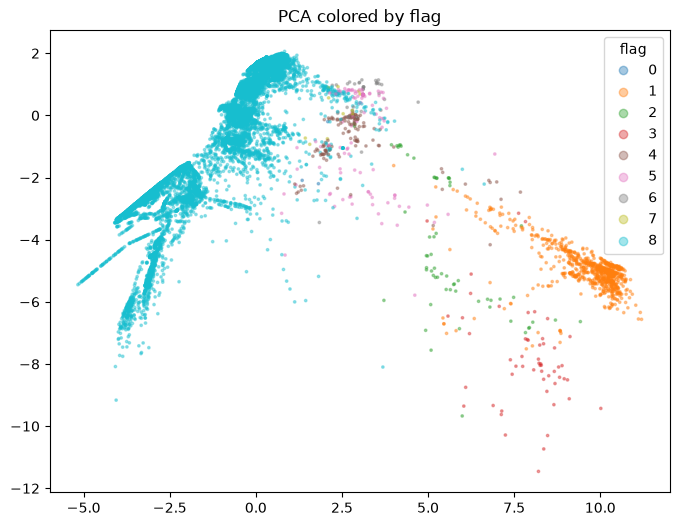

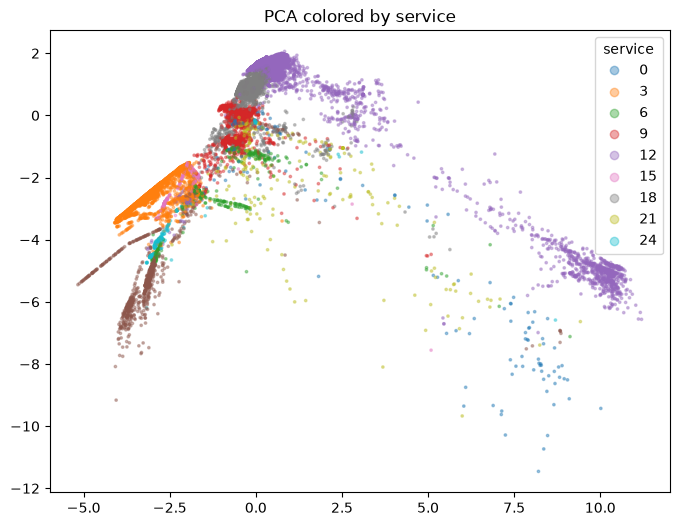

In [72]:
for choice in ['protocol_type','flag','service']:
    plt.figure(figsize=(8,6))
    scatter = plt.scatter(pca_result[:,0], pca_result[:,1], s=3, alpha=0.4,
                        c=normal_df[choice].astype('category').cat.codes, cmap='tab10')
    plt.title(f"PCA colored by {choice}")
    plt.legend(*scatter.legend_elements(), title=f"{choice}")
    plt.show()

**PCA colored by protocol_type / flag / service (normal-only data):**

- **Main top-center cluster:** dominated by `protocol_type=tcp` + `flag=SF` (clean
  close), but contains a MIX of several different `service` values — so this "main
  blob" is actually several services sharing the same tcp+SF fingerprint.

- **Left diagonal "arms":** dominated by `protocol_type=udp` + still mostly `flag=SF`,
  but the service coloring shows each individual arm corresponds to ONE specific
  service — each service fans out into its own arm because it has a distinct
  numeric footprint.

- **Isolated cluster (far right, PC1≈10):** its own distinct `service`, its own
  distinct `flag` (not SF), still tcp. A genuinely separate behavioral fingerprint —
  one specific service+flag combo with very different numeric behavior from
  everything else.


The multiple "modes" seen in Phase 5's PCA are NOT explained by any single
categorical column alone — they emerge from **combinations** of
`protocol_type` + `service` + `flag` together. Each combo carves out its own
region because the numeric features (byte counts, rates, etc.) behave
differently depending on the type of connection.


A single  unimodal generative approach (one global copula, one
plain Gaussian model) would blur these distinct combos together and generate
synthetic points in "empty space" between real modes — exactly what a
multivariate detector (Isolation Forest) would flag as unrealistic.

---
**Fitting ECOD and Isolation Forest**

In [73]:
# Encode categoricals for the detectors (they need numeric input)
full_encoded = pd.get_dummies(df[numeric_cols + ['protocol_type', 'service', 'flag']],
                                columns=['protocol_type', 'service', 'flag'])
y_true = df['is_anomaly'].values

# Scale (helps IForest split behavior, doesn't hurt ECOD)
X_scaled = StandardScaler().fit_transform(full_encoded)

# Fit ECOD
ecod = ECOD()
ecod.fit(X_scaled)
ecod_scores = ecod.decision_scores_  # higher = more abnormal

# Fit IForest (match brief's spec: 10 seeds x 500 trees — start with 1 seed for now)
iforest = IForest(n_estimators=500, random_state=42)
iforest.fit(X_scaled)
iforest_scores = iforest.decision_scores_

# AUPRC against true labels
print("ECOD AUPRC:", average_precision_score(y_true, ecod_scores))
print("IForest AUPRC:", average_precision_score(y_true, iforest_scores))

ECOD AUPRC: 0.7742609806500369
IForest AUPRC: 0.6012194504755539


In [74]:
# ECOD exposes per-dimension outlier scores
feature_names = full_encoded.columns
O = ecod.O  # per-feature outlier scores, shape (n_samples, n_features)

# Average contribution per feature, for rows that ARE anomalies
mean_contrib = pd.Series(O[y_true == 1].mean(axis=0), index=feature_names)
print(mean_contrib.sort_values(ascending=False).head(15))

count                          1.938335
same_srv_rate                  1.775592
dst_host_same_srv_rate         1.659353
dst_host_srv_count             1.637272
dst_host_diff_srv_rate         1.570050
diff_srv_rate                  1.507628
srv_count                      1.351471
src_bytes                      1.302084
dst_host_serror_rate           1.185934
dst_host_same_src_port_rate    1.150212
serror_rate                    1.116725
dst_host_srv_serror_rate       1.097643
srv_serror_rate                1.064530
flag_S0                        1.043549
flag_SF                        1.019860
dtype: float64


In [75]:
# Rough proxy: check correlation between each feature and the anomaly score for Isolation Forest
corr_with_score = pd.DataFrame(X_scaled, columns=feature_names).corrwith(pd.Series(iforest_scores))
print(corr_with_score.abs().sort_values(ascending=False).head(15))

logged_in                      0.657591
rerror_rate                    0.614550
srv_rerror_rate                0.613218
dst_host_srv_rerror_rate       0.604085
dst_host_rerror_rate           0.601112
dst_host_srv_count             0.562528
service_http                   0.561206
dst_host_diff_srv_rate         0.518540
flag_REJ                       0.489485
dst_host_same_srv_rate         0.468047
flag_SF                        0.459177
dst_host_same_src_port_rate    0.434519
diff_srv_rate                  0.375381
protocol_type_tcp              0.328104
count                          0.318999
dtype: float64


/Users/han./Desktop/CS5344/.venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/han./Desktop/CS5344/.venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


**Purpose:** unlike Phases 1–5 (which studied the normal data itself), this phase
studies the two FIXED detectors that will grade your submission — to see which
features they actually rely on to separate normal from abnormal. Fit on the full
labeled dataset (normal + abnormal), since the detectors need both classes to learn
what "typical vs. outlier" means.


ECOD scores each feature separately, then sums the scores — so we can directly read
which features drove the highest "this looks weird" scores for genuinely abnormal rows.

**Top features:**
`count`, `same_srv_rate`, `dst_host_same_srv_rate`, `dst_host_srv_count`,
`dst_host_diff_srv_rate`, `diff_srv_rate`, `srv_count`, `src_bytes`,
`dst_host_serror_rate`, `dst_host_same_src_port_rate`, `serror_rate`,
`dst_host_srv_serror_rate`, `srv_serror_rate`, `flag_S0`, `flag_SF`

We also measured whether a feature's value tends to rise/fall together with IForest's
anomaly score across all rows — an indirect signal of what the trees are likely
splitting on.

**Top features:**
`logged_in`, `rerror_rate`, `srv_rerror_rate`, `dst_host_srv_rerror_rate`,
`dst_host_rerror_rate`, `dst_host_srv_count`, `service_http`,
`dst_host_diff_srv_rate`, `flag_REJ`, `dst_host_same_srv_rate`, `flag_SF`,
`dst_host_same_src_port_rate`, `diff_srv_rate`, `protocol_type_tcp`, `count`


| Shared by both detectors | ECOD-specific | IForest-specific |
|---|---|---|
| `count`, `dst_host_srv_count`, `dst_host_diff_srv_rate`, `diff_srv_rate`, `dst_host_same_srv_rate`, `flag_SF` | `same_srv_rate`, `src_bytes`, `serror_rate` family, `flag_S0` | `logged_in`, `rerror_rate` family, `service_http`, `flag_REJ`, `protocol_type_tcp` |

In conclusion, 

- **Shared features** (count/service-diversity rates, `flag_SF`) are the **highest
  priority** to get exactly right in synthetic data — both scoring components
  depend on them.
- **ECOD is sensitive to the SYN-error family** (`serror_rate`, `flag_S0`); **IForest
  is sensitive to the REJ-error family** (`rerror_rate`, `flag_REJ`) and `logged_in`.
  They are NOT redundant judges — they key off different error signatures.
  → Synthetic data must realistically preserve **both** error-rate families and
  **all three** relevant flags (`SF`, `S0`, `REJ`), not just one.
- **`service_http`** appearing for IForest but not ECOD suggests categorical
  *identity* (not just derived numeric rates) matters specifically to IForest's
  multivariate splits.

This reinforces the Phase 4 (correlation clusters) and Phase 5 (multi-modal
categorical-driven structure) conclusions: the features both detectors rely on
span BOTH the numeric rate clusters (serror/rerror families, count/diversity
rates) AND the categorical combo (`flag`, `service`, `protocol_type`). A method
that only gets individual marginals right, or only preserves numeric correlations
without the categorical conditioning, will miss what actually drives detection.

**→ Final method direction:** condition generation on the categorical combo
(`protocol_type`, `service`, `flag`) first, then generate numeric features —
with particular care to preserve the count/diversity-rate cluster and BOTH
error-rate families (serror + rerror) — within each combo.

1. Roll a random (protocol_type, service, flag) combo, weighted by how common each combo is in real normal data
2. Using only real rows matching that combo, generate the 38 numeric values
3. For the numeric values that are known to move together (count-pair, serror-family, rerror-family, the root/compromise cluster), generate those as a group that respects their correlation — not as independent random draws

- Multivariate Gaussian / GMM: Instead of fitting each feature separately, you fit one joint distribution that includes a covariance matrix — literally a table of "how much does feature A move when feature B moves." When you sample from it, correlated features come out together automatically, because the covariance matrix enforces it mathematically. GMM = same idea, but multiple Gaussians blended together (useful if even within one categorical combo, there's still sub-structure/multiple modes).
- Copula: Splits the job into two separate pieces — (a) fit each feature's own individual shape (your Phase 2/3 work: Bernoulli+lognormal, 3-part rate models, etc.) completely separately, then (b) fit a separate "glue" model that only captures how features rank/move together (ignoring their individual shapes). At generation time, you sample the "glue" pattern first, then convert it into each feature's real shape. Advantage: you get to keep your carefully-tailored Phase 2/3 marginal distributions (Bernoulli for near-constant features, log-normal for skewed ones) exactly as-is, while still capturing correlation.
- Conditional VAE: A neural network that learns to generate all 38 numeric values at once, in a single forward pass, given the categorical combo as an input. It doesn't need you to manually specify "these features are correlated" — it learns the joint structure (including correlations) directly from data during training. Trade-off: more flexible/less manual work, but harder to point to why it preserves any specific correlation (this matters for the "explainability" part of your grade).